# Minor Project 4

## Unsupervised Learning

## Credit Card Fraud Detection Using Unsupervised Learning

### 1. Problem Understanding

#### 1.1 What is fraud detection?
 ##### Fraud detection is the process of identifying financial transactions that may be unauthorized or suspicious.
#### 1.2 Why is fraud detection difficult?
 ##### Fraudulent transactions are very rare compared with genuine transactions. Fraud patterns can also change over time, and confirmed fraud labels may not be immediately available.
#### 1.3 Why use unsupervised learning?
 ##### Unsupervised learning can find unusual patterns without depending on labelled examples. This is useful when fraud labels are missing, incomplete, or delayed.

### 2. Exploratory Data Analysis


#### 2.1 Data Shape
 ##### To identify the number of transactions (rows) and features (columns) in the dataset.

In [1]:
# Import Pandas for data analysis
import pandas as pd

# Load the credit card transaction dataset
df = pd.read_csv("creditcard.csv")

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display the number of transactions (rows)
print("Total transactions:", df.shape[0])

# Display the number of features (columns)
print("Total columns:", df.shape[1])

# Display the first five rows to understand the dataset structure
display(df.head())

Dataset shape: (284807, 31)
Total transactions: 284807
Total columns: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


#### 2.2 Feature Distribution
  ##### To understand how transaction amounts and other numerical features are distributed.

In [2]:
# Identify numerical features
# Display the data types of all columns
print("Column data types:")
print(df.dtypes)

# Display summary statistics for numerical columns
# These include count, mean, standard deviation, minimum and maximum
display(df.describe())

Column data types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


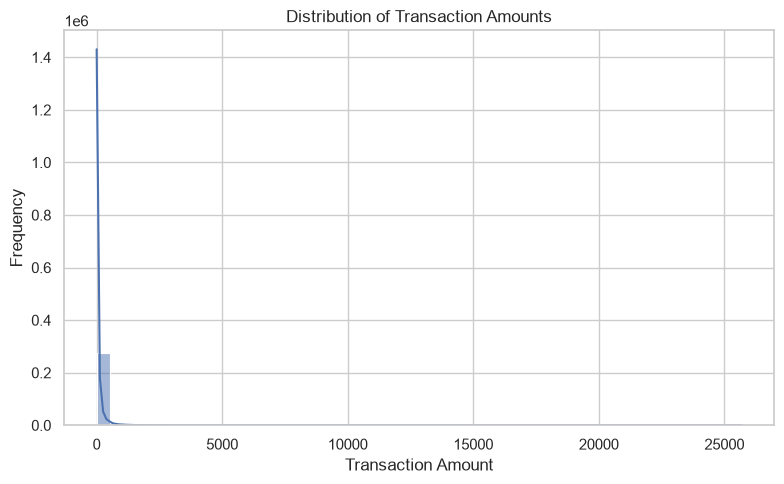

In [4]:
# Transaction amount distribution
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean style for the chart
sns.set_theme(style="whitegrid")

# Plot the distribution of transaction amounts
plt.figure(figsize=(8, 5)) # plt.figure() sets the chart size.
sns.histplot(df["Amount"], bins=50, kde=True) # sns.histplot() displays the frequency of transaction amounts.

# Add labels and a title for easy interpretation
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

# Display the chart
plt.tight_layout()
plt.show()

#### 2.3 Class Imbalance Observation
   ##### To determine whether fraudulent transactions are much less frequent than legitimate transactions.

In [5]:
# Count and percentage of each class
# Count the number of transactions in each class
# Class 0 represents legitimate transactions
# Class 1 represents fraudulent transactions
class_counts = df["Class"].value_counts().sort_index()

# Calculate the percentage of each class
class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

# Display the number of transactions in each class
print("Class Counts:")
print(class_counts)

# Display the percentage of each class
print("\nClass Percentages:")
print(class_percentages.round(4))

Class Counts:
Class
0    284315
1       492
Name: count, dtype: int64

Class Percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


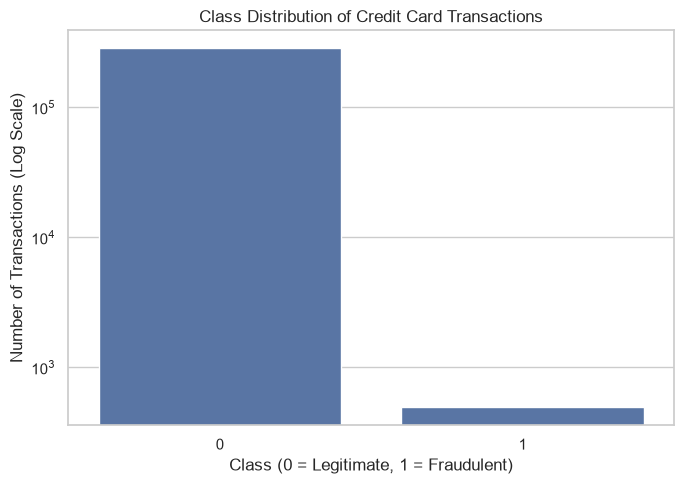

In [6]:
# Visualize class imbalance
# Create a bar chart showing the number of transactions in each class
plt.figure(figsize=(7, 5))

# Plot the count of legitimate and fraudulent transactions
ax = sns.barplot(x=class_counts.index, y=class_counts.values)

# Use a logarithmic scale to make the smaller class more visible
ax.set_yscale("log")

# Add the chart title and axis labels
plt.title("Class Distribution of Credit Card Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Number of Transactions (Log Scale)")

# Display the chart
plt.tight_layout()
plt.show()

##### The chart shows a significant class imbalance in the credit card transaction dataset. Legitimate transactions (Class 0) are much more frequent than fraudulent transactions (Class 1). Therefore, identifying fraudulent transactions is challenging because they represent only a very small proportion of the dataset.

#### 2.4 Key Insights from EDA
  ##### To summarize the important observations obtained from the dataset analysis.

In [7]:
# Calculate the total number of transactions
total_transactions = len(df)

# Calculate the number of legitimate transactions
legitimate_count = (df["Class"] == 0).sum()

# Calculate the number of fraudulent transactions
fraud_count = (df["Class"] == 1).sum()

# Calculate the percentage of fraudulent transactions
fraud_percentage = (fraud_count / total_transactions) * 100

# Calculate the average transaction amount
average_amount = df["Amount"].mean()

# Calculate the median transaction amount
median_amount = df["Amount"].median()

# Display the key findings
print("KEY EDA INSIGHTS")
print("-" * 40)

print(f"Total transactions: {total_transactions}")
print(f"Legitimate transactions: {legitimate_count}")
print(f"Fraudulent transactions: {fraud_count}")
print(f"Fraud percentage: {fraud_percentage:.4f}%")

print(f"Average transaction amount: {average_amount:.2f}")
print(f"Median transaction amount: {median_amount:.2f}")

# Compare the mean and median to get a basic indication of skewness
if average_amount > median_amount:
    print("Amount observation: The distribution may be positively skewed.")
elif average_amount < median_amount:
    print("Amount observation: The distribution may be negatively skewed.")
else:
    print("Amount observation: Mean and median are equal.")

KEY EDA INSIGHTS
----------------------------------------
Total transactions: 284807
Legitimate transactions: 284315
Fraudulent transactions: 492
Fraud percentage: 0.1727%
Average transaction amount: 88.35
Median transaction amount: 22.00
Amount observation: The distribution may be positively skewed.


 **1. Data Shape:** The dataset contains 284,807 transactions and 31 columns.

**2. Legitimate Transactions:** There are 284,315 legitimate transactions (Class 0).

**3. Fraudulent Transactions:** There are 492 fraudulent transactions (Class 1).

**4. Class Imbalance:** Fraudulent transactions account for only 0.1727% of the dataset, indicating a significant class imbalance.

**5. Transaction Amount:** The average transaction amount is 88.35, while the median is 22.00.

**6. Feature Distribution:** The average transaction amount is greater than the median, suggesting a positively skewed distribution.

**7. Key Observation:** Fraudulent transactions are rare compared to legitimate transactions, making fraud detection challenging.

### 3. Data Preprocessing

#### 3.1 Feature Selection Decisions
##### The credit card dataset contains transaction features such as Time, V1 to V28, and Amount. The Class column represents the actual transaction label, where 0 indicates a legitimate transaction and 1 indicates a fraudulent transaction.

##### Since this project uses unsupervised learning, the Class column is excluded from model training and stored separately for final evaluation. The remaining 30 features are selected for analysis.¶

In [8]:
# Separate transaction features from the actual fraud labels
# The Class column must not be used during unsupervised model training
X = df.drop(columns=["Class"])

# Store the actual labels separately for final evaluation
y = df["Class"]

# Display the selected features and dataset dimensions
print("Selected features:", X.columns.tolist())
print("Feature dataset shape:", X.shape)

Selected features: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']
Feature dataset shape: (284807, 30)


#### 3.2 Handling Scaling


##### The selected features have different numerical ranges. For example, the Amount and Time features may have different scales from the PCA-transformed features (V1 to V28).

##### Therefore, StandardScaler is used to standardize the numerical features. This is important for K-Means because it calculates distances between data points, and features with larger scales could otherwise dominate those calculations.

In [9]:
# Import StandardScaler for feature standardization
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Standardize the selected transaction features
X_scaled_array = scaler.fit_transform(X)

# Convert the scaled array into a DataFrame
# Preserve the original feature names and row indices
X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=X.columns,
    index=X.index
)

# Display the first five rows of the scaled dataset
display(X_scaled.head())

# Display the dimensions after scaling
print("Shape after scaling:", X_scaled.shape)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-1.996583,-0.694242,-0.044075,1.672773,0.973366,-0.245117,0.347068,0.193679,0.082637,0.331128,...,0.326118,-0.024923,0.382854,-0.176911,0.110507,0.246585,-0.392170,0.330892,-0.063781,0.244964
1,-1.996583,0.608496,0.161176,0.109797,0.316523,0.043483,-0.061820,-0.063700,0.071253,-0.232494,...,-0.089611,-0.307377,-0.880077,0.162201,-0.561131,0.320694,0.261069,-0.022256,0.044608,-0.342475
2,-1.996562,-0.693500,-0.811578,1.169468,0.268231,-0.364572,1.351454,0.639776,0.207373,-1.378675,...,0.680975,0.337632,1.063358,1.456320,-1.138092,-0.628537,-0.288447,-0.137137,-0.181021,1.160686
3,-1.996562,-0.493325,-0.112169,1.182516,-0.609727,-0.007469,0.936150,0.192071,0.316018,-1.262503,...,-0.269855,-0.147443,0.007267,-0.304777,-1.941027,1.241904,-0.460217,0.155396,0.186189,0.140534
4,-1.996541,-0.591330,0.531541,1.021412,0.284655,-0.295015,0.071999,0.479302,-0.226510,0.744326,...,0.529939,-0.012839,1.100011,-0.220123,0.233250,-0.395202,1.041611,0.543620,0.651816,-0.073403


Shape after scaling: (284807, 30)


In [10]:
# Verify the Scaling Results
# Verify that the scaled features have approximately zero mean
print("Mean of scaled features:")
print(X_scaled.mean().round(3))

# Verify that the scaled features have approximately unit standard deviation
print("\nStandard deviation of scaled features:")
print(X_scaled.std().round(3))

Mean of scaled features:
Time     -0.0
V1        0.0
V2       -0.0
V3       -0.0
V4        0.0
V5       -0.0
V6        0.0
V7        0.0
V8        0.0
V9       -0.0
V10       0.0
V11      -0.0
V12      -0.0
V13      -0.0
V14       0.0
V15       0.0
V16       0.0
V17       0.0
V18       0.0
V19       0.0
V20      -0.0
V21       0.0
V22       0.0
V23       0.0
V24       0.0
V25       0.0
V26       0.0
V27       0.0
V28      -0.0
Amount   -0.0
dtype: float64

Standard deviation of scaled features:
Time      1.0
V1        1.0
V2        1.0
V3        1.0
V4        1.0
V5        1.0
V6        1.0
V7        1.0
V8        1.0
V9        1.0
V10       1.0
V11       1.0
V12       1.0
V13       1.0
V14       1.0
V15       1.0
V16       1.0
V17       1.0
V18       1.0
V19       1.0
V20       1.0
V21       1.0
V22       1.0
V23       1.0
V24       1.0
V25       1.0
V26       1.0
V27       1.0
V28       1.0
Amount    1.0
dtype: float64


#### 3.3 Justification of Preprocessing Steps

**1. Feature selection:** The Class column was excluded from model training because the project requires unsupervised learning.

**2. Feature scaling:** StandardScaler was applied to standardize the numerical features and reduce the influence of differences in their scales.

**3. Label preservation:** The actual fraud labels were stored separately and reserved for evaluating the model predictions at the end.

**4. Data preservation:** The original dataset was retained, while the selected and scaled features were stored in X_scaled for subsequent modelling.

### 4. Clustering Approach

#### 4.1 Method Selection Reasoning

##### K-Means Clustering is selected as the clustering method for credit card fraud detection. It groups transactions based on similarities in their feature values.

##### The algorithm divides transactions into clusters by assigning each transaction to the nearest cluster center. Transactions that differ significantly from the characteristics of their assigned cluster may be considered potentially suspicious.

#####  K-Means is selected because it is a simple, widely used unsupervised learning algorithm that allows us to study transaction patterns without using fraud labels during model building.

##### The features are scaled before clustering because features with larger numerical values could otherwise dominate the distance calculations.

#### 4.2 Parameter Tuning Logic

##### The number of clusters (K) is an important parameter in K-Means. A small number of clusters may not capture the different transaction patterns, while too many clusters may make interpretation difficult.

##### To select a suitable value of K, different values are tested using the Silhouette Score. A higher Silhouette Score generally indicates better separation between clusters.

##### The model is tested with K = 2, 3, 4, and 5. The score and computational cost are considered when selecting the final value. The random_state parameter is fixed to make the results reproducible.

##### The selected K is used to train the final K-Means model.

K = 2, Silhouette Score = 0.0675
K = 3, Silhouette Score = 0.0726
K = 4, Silhouette Score = 0.0726
K = 5, Silhouette Score = 0.0753


,Number of Clusters (K),Silhouette Score
0,2,0.067459
1,3,0.072570
2,4,0.072564
3,5,0.075291


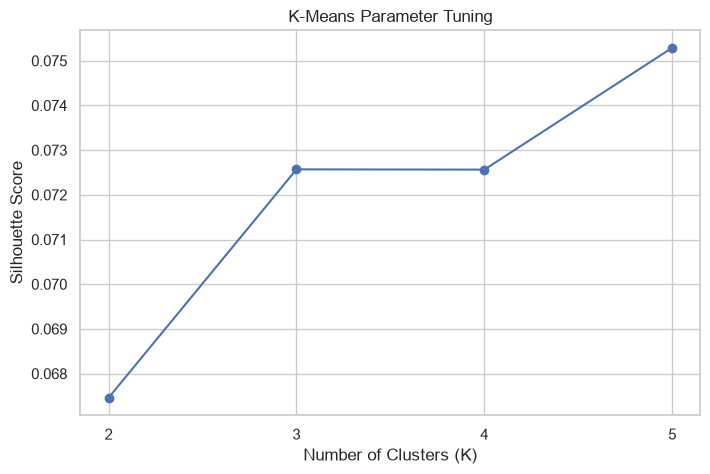

Selected number of clusters: 5


In [11]:
## test different values of K

# Import the required libraries for clustering and evaluation

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.utils import resample

# Use a sample to reduce computation time during parameter tuning
tuning_size = min(10000, len(X_scaled))

# X_tuning: Uses a sample of transactions to reduce the time required for parameter testing.
X_tuning = resample(
    X_scaled,
    n_samples=tuning_size,
    random_state=42
)

# Test different numbers of clusters
k_values = [2, 3, 4, 5]
silhouette_scores = []

for k in k_values:

    # Create the K-Means model with the current value of K
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=5, # Runs K-Means with five initial centroid configurations and selects the best result.
        max_iter=100 #Limits the number of iterations per initialization.
    )

    # Fit the model using the tuning sample
    cluster_labels = kmeans.fit_predict(X_tuning)

    # Calculate the Silhouette Score to evaluate cluster separation
    score = silhouette_score(X_tuning, cluster_labels)
    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Display the scores for comparison
tuning_results = pd.DataFrame({
    "Number of Clusters (K)": k_values,
    "Silhouette Score": silhouette_scores
})

display(tuning_results)

# Visualize how the score changes with K
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Parameter Tuning")
plt.xticks(k_values)
plt.grid(True)
plt.show()

# Select the K value with the highest Silhouette Score
best_k = k_values[silhouette_scores.index(max(silhouette_scores))]

print("Selected number of clusters:", best_k) # Selects the tested K with the highest Silhouette Score.

#### 4.3 Train the K-Means Model

In [12]:
# Train the final K-Means model using the selected number of clusters
kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=5,
    max_iter=100
)

# Assign each transaction to its nearest cluster center
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Store cluster assignments for analysis
cluster_results = pd.DataFrame({
    "Cluster": cluster_labels
}, index=X_scaled.index if isinstance(X_scaled, pd.DataFrame) else None) # cluster_results: Stores the cluster assignment for every transaction.

# Count the transactions assigned to each cluster
cluster_counts = cluster_results["Cluster"].value_counts().sort_index()

print("Number of transactions in each cluster:")
print(cluster_counts)

# Display the percentage of transactions in each cluster
print("\nPercentage of transactions in each cluster:")
print((cluster_counts / len(cluster_results) * 100).round(2))

Number of transactions in each cluster:
Cluster
0     36603
1    112779
2     99086
3     19878
4     16461
Name: count, dtype: int64

Percentage of transactions in each cluster:
Cluster
0    12.85
1    39.60
2    34.79
3     6.98
4     5.78
Name: count, dtype: float64


#### 4.4 Cluster Interpretation

##### After training the K-Means model, the transactions are grouped into different clusters based on similarities in their scaled features.

##### The number and percentage of transactions in each cluster are examined to understand the distribution of transaction patterns. The average distance of transactions from their assigned cluster centers is also calculated.

##### Transactions with unusually large distances from their assigned cluster centers may represent unusual transaction patterns and can be investigated further.

##### However, a small cluster or a large distance does not necessarily indicate fraud. K-Means identifies similarities and differences in transaction patterns, rather than directly classifying transactions as fraudulent or legitimate.

Cluster distribution:
Cluster
0     36603
1    112779
2     99086
3     19878
4     16461
Name: count, dtype: int64

Cluster summary:


,Transaction_Count,Average_Distance,Maximum_Distance
Cluster,,,
0,36603,4.8390,217.7522
1,112779,4.1477,91.0433
2,99086,4.2999,79.4667
3,19878,4.7328,78.0653
4,16461,4.1490,32.5875


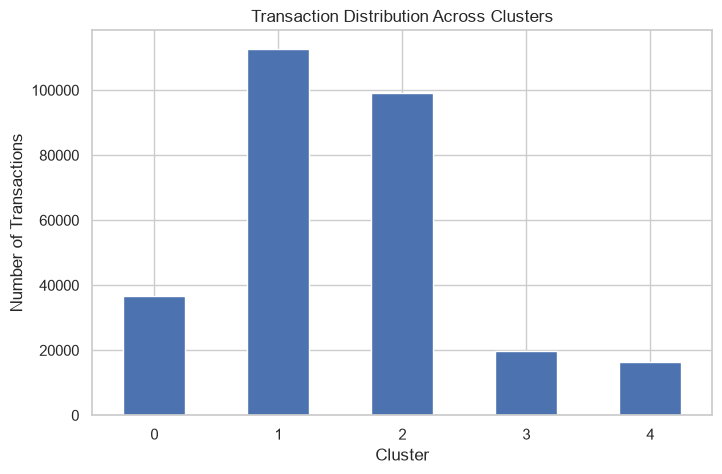

Distance threshold: 14.9514
Potential anomalies identified: 2849
Percentage of potential anomalies: 1.0 %


In [16]:
import numpy as np
# Calculate the distance of each transaction from every cluster center
distances = kmeans_final.transform(X_scaled)

# Find the distance between each transaction and its assigned center
assigned_distances = distances[
    np.arange(len(cluster_labels)),
    cluster_labels
]

# Add cluster assignments and distances to the results
cluster_results["Distance_From_Center"] = assigned_distances

# Display the number of transactions in each cluster
print("Cluster distribution:")
print(cluster_results["Cluster"].value_counts().sort_index())

# Calculate the average distance from the center for each cluster
cluster_summary = cluster_results.groupby("Cluster").agg(
    Transaction_Count=("Cluster", "size"),
    Average_Distance=("Distance_From_Center", "mean"),
    Maximum_Distance=("Distance_From_Center", "max")
)

print("\nCluster summary:")
display(cluster_summary.round(4))

# Plot the number of transactions in each cluster
cluster_results["Cluster"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Cluster")
plt.ylabel("Number of Transactions")
plt.title("Transaction Distribution Across Clusters")
plt.xticks(rotation=0)
plt.show()

# Use the 99th percentile of distances to identify unusually distant transactions
distance_threshold = np.percentile(assigned_distances, 99)

# Flag transactions with unusually large distances for further investigation
cluster_results["Potential_Anomaly"] = (
    cluster_results["Distance_From_Center"] > distance_threshold
)

print("Distance threshold:", round(distance_threshold, 4))

print("Potential anomalies identified:",
    cluster_results["Potential_Anomaly"].sum())

print("Percentage of potential anomalies:",
    round(cluster_results["Potential_Anomaly"].mean() * 100, 2),"%")

##### The Silhouette Score was used to test K = 2, 3, 4, and 5. Among these values, K = 5 achieved the highest score of 0.075291 and was selected for the final K-Means model.

##### The model grouped 284,807 transactions into five clusters without using the actual fraud labels. Cluster 1 contained the largest number of transactions (112,779; 39.60%), while Cluster 4 contained the smallest number (16,461; 5.78%).

##### Using the 99th-percentile distance threshold of 14.9514, 2,849 transactions (approximately 1% of the dataset) were flagged as potential anomalies. These transactions may have unusual patterns and require further investigation; they are not necessarily fraudulent.

### 5. Anomaly Detection Approach 

#### 5.1 Model Selection and Parameter Decisions

##### Isolation Forest is an unsupervised learning algorithm used to identify unusual transactions. It does not require actual fraud labels during model training.

##### The following parameters are selected:
##### - n_estimators=100: Builds 100 isolation trees.
##### - contamination="auto": Uses the default method to determine the anomaly threshold.
##### - random_state=42: Helps produce reproducible results.
##### - max_samples="auto": Uses the default sample size for each tree.

In [17]:
# Train the Model

# Import the Isolation Forest algorithm
from sklearn.ensemble import IsolationForest

# Create the Isolation Forest model
isolation_model = IsolationForest(
    n_estimators=100,       # Number of isolation trees
    contamination="auto",   # Automatically determine the threshold
    random_state=42,        # Ensure reproducible results
    max_samples="auto"      # Use the default sample size
)

# Train the model using scaled features only
# Do not include the actual Class fraud label in X_scaled
isolation_model.fit(X_scaled)

print("Isolation Forest model trained successfully.")

Isolation Forest model trained successfully.


#### 5.2 Anomaly Detection Results

##### After training, the model predicts whether each transaction is normal or anomalous.
##### - 1 represents a normal transaction.
##### - -1 represents an anomalous transaction.
##### An anomalous transaction is potentially suspicious, but it is not necessarily fraudulent.

In [18]:
# Detect Anomalies

# Predict whether each transaction is normal or anomalous
anomaly_predictions = isolation_model.predict(X_scaled) # predict() generates the anomaly predictions.

# Count normal and anomalous transactions
normal_count = np.sum(anomaly_predictions == 1) # np.sum() counts normal and anomalous transactions.
anomaly_count = np.sum(anomaly_predictions == -1)

# Calculate the percentage of transactions flagged as anomalies
total_transactions = len(anomaly_predictions)
anomaly_percentage = (anomaly_count / total_transactions) * 100 # anomaly_percentage calculates the percentage flagged as anomalous.

# Display the results
print("Total Transactions:", total_transactions)
print("Normal Transactions:", normal_count)
print("Anomalous Transactions:", anomaly_count)
print("Anomaly Percentage:", round(anomaly_percentage, 4), "%")

Total Transactions: 284807
Normal Transactions: 274912
Anomalous Transactions: 9895
Anomaly Percentage: 3.4743 %


#### 5.3 Output Interpretation

##### he model's predictions help identify transactions that differ from the general patterns in the dataset.
##### - Normal transactions: Transactions the model considers consistent with learned patterns.
##### - Anomalous transactions: Transactions the model considers unusual and worthy of further investigation.
##### - Anomaly percentage: The proportion of transactions flagged as anomalous.

In [19]:
# Display the Detection Results

# Store predictions in a DataFrame for easy interpretation
anomaly_results = pd.DataFrame({
    "Anomaly_Prediction": anomaly_predictions
}) # DataFrame() stores the predictions in tabular form.

# Convert numerical predictions into readable descriptions
anomaly_results["Transaction_Status"] = np.where(
    anomaly_results["Anomaly_Prediction"] == -1,
    "Anomalous",
    "Normal"
) # np.where() converts predictions into readable transaction statuses.

# Display the first five transaction results
print(anomaly_results.head()) # head() displays the first five results.

# Display the total count of each transaction status
print("\nTransaction Status Summary:")
print(anomaly_results["Transaction_Status"].value_counts()) # value_counts() summarizes the number of transactions in each category.

   Anomaly_Prediction Transaction_Status
0                   1             Normal
1                   1             Normal
2                   1             Normal
3                   1             Normal
4                   1             Normal

Transaction Status Summary:
Transaction_Status
Normal       274912
Anomalous      9895
Name: count, dtype: int64


##### Isolation Forest was used to detect anomalous credit card transactions without using actual fraud labels during training. The model classified transactions as normal or anomalous based on their learned patterns. Transactions identified as anomalous can be investigated further to determine whether they are fraudulent. However, anomaly detection alone cannot confirm fraud.

### 6. Comparison of Methods

#### 6.1 Compare the Number of Anomalies Detected

##### K-Means and Isolation Forest identify unusual transactions using different approaches. K-Means groups transactions into clusters based on similarity, while Isolation Forest identifies transactions that are easier to isolate from the remaining data. Comparing the number of anomalies detected helps us understand how differently the two methods identify suspicious transactions.

In [20]:
# Compare the number of anomalies detected by both methods

# Count anomalies detected by K-Means
kmeans_anomalies = cluster_results["Potential_Anomaly"].sum()

# Count anomalies detected by Isolation Forest (-1 indicates an anomaly)
isolation_anomalies = (anomaly_predictions == -1).sum()

# Calculate the percentage of anomalies detected by each method
total_transactions = len(anomaly_predictions)

kmeans_percentage = (kmeans_anomalies / total_transactions) * 100
isolation_percentage = (isolation_anomalies / total_transactions) * 100

# Display the comparison in a table
comparison_df = pd.DataFrame({
    "Method": ["K-Means", "Isolation Forest"],
    "Anomalies Detected": [kmeans_anomalies, isolation_anomalies],
    "Percentage (%)": [kmeans_percentage, isolation_percentage]
})

print(comparison_df.to_string(index=False))

# Identify which method detected more anomalies
if kmeans_anomalies > isolation_anomalies:
    print("\nK-Means detected more anomalies.")
elif isolation_anomalies > kmeans_anomalies:
    print("\nIsolation Forest detected more anomalies.")
else:
    print("\nBoth methods detected the same number of anomalies.")

          Method  Anomalies Detected  Percentage (%)
         K-Means                2849        1.000327
Isolation Forest                9895        3.474283

Isolation Forest detected more anomalies.


#### 6.2 Logical Reasoning Behind the Results

##### K-Means and Isolation Forest detect anomalies using different principles.
##### - K-Means Clustering: Groups transactions into five clusters based on similarities. Transactions that are unusually far from their assigned cluster centres are identified as potential anomalies. The distance threshold determines which transactions are flagged.
##### - Isolation Forest: Identifies unusual transactions by isolating them from other transactions. Unusual patterns that are easier to isolate are more likely to be classified as anomalies.
##### - Reason for different results: K-Means depends on cluster structure and distance thresholds, whereas Isolation Forest uses isolation-based decision rules. Therefore, the number of anomalies detected by the two methods may differ.
##### - Interpretation: Detecting more anomalies does not automatically mean a method is better. The flagged transactions may include both genuine fraud and legitimate transactions with unusual patterns.

#### 6.3 Strengths and Weaknesses of Both Methods

| Method | Strengths | Weaknesses |
|---|---|---|
| K-Means Clustering | Groups similar transactions, provides understandable clusters, and identifies transactions far from cluster centres. | Requires choosing the number of clusters and a distance threshold. May not identify every type of unusual transaction. |
| Isolation Forest | Designed for anomaly detection, identifies unusual patterns, and does not require fraud labels during training. | May flag legitimate transactions as anomalies and may miss some fraudulent transactions. Its results depend on model parameters. |

### 7. Bonus Evaluation 

#### 7.1 Compare Predictions with Actual Fraud Labels
##### Compare the anomalies detected by K-Means and Isolation Forest with the actual fraud labels to understand how well each method identifies fraudulent transactions.

In [29]:
# Get the actual fraud labels for final evaluation
# 0 = Legitimate, 1 = Fraudulent
actual_labels = df['Class'].astype(int).to_numpy()

# Calculate the distance from each transaction to its nearest cluster centre
kmeans_distances = kmeans_final.transform(X_scaled).min(axis=1)

# Use the existing anomaly threshold from Section 4
kmeans_predictions = (
    kmeans_distances > distance_threshold
).astype(int)

# Get Isolation Forest predictions
# -1 = Anomaly, 1 = Normal
isolation_raw_predictions = isolation_model.predict(X_scaled)

# Convert predictions into binary labels
# 0 = Normal, 1 = Anomaly
isolation_predictions = np.where(
    isolation_raw_predictions == -1, 1, 0
)

# Compare actual labels with both model predictions
comparison_df = pd.DataFrame({
    'Actual_Fraud': actual_labels,
    'KMeans_Prediction': kmeans_predictions,
    'Isolation_Forest_Prediction': isolation_predictions
})

# Display the first five comparisons
comparison_df.head()

,Actual_Fraud,KMeans_Prediction,Isolation_Forest_Prediction
0,0,0,0
1,0,0,0
2,0,0,0
3,0,0,0
4,0,0,0


In [30]:
# Display the total number of actual fraud transactions
print("Actual Fraud:", np.sum(actual_labels))

# Display the total number of anomalies detected by K-Means
print("K-Means Anomalies:", np.sum(kmeans_predictions))

# Display the total number of anomalies detected by Isolation Forest
print("Isolation Forest Anomalies:", np.sum(isolation_predictions))

# Display transactions where at least one model detected an anomaly
comparison_df[
    (comparison_df['KMeans_Prediction'] == 1) |
    (comparison_df['Isolation_Forest_Prediction'] == 1)
].head(10)

Actual Fraud: 492
K-Means Anomalies: 2849
Isolation Forest Anomalies: 9895


,Actual_Fraud,KMeans_Prediction,Isolation_Forest_Prediction
51,0,0,1
82,0,0,1
83,0,0,1
134,0,0,1
140,0,0,1
145,0,0,1
146,0,0,1
150,0,0,1
164,0,1,1
174,0,0,1


##### The actual fraud labels are compared with the predictions generated by K-Means and Isolation Forest. K-Means detected 2,849 anomalies, whereas Isolation Forest detected 9,895 anomalies. The comparison shows that some transactions identified as anomalies are actually legitimate transactions. Therefore, anomaly detection does not directly confirm fraud, and further evaluation is required.

#### 7.2 Confusion Matrix
 ##### A confusion matrix evaluates how accurately each model identifies fraudulent and legitimate transactions.

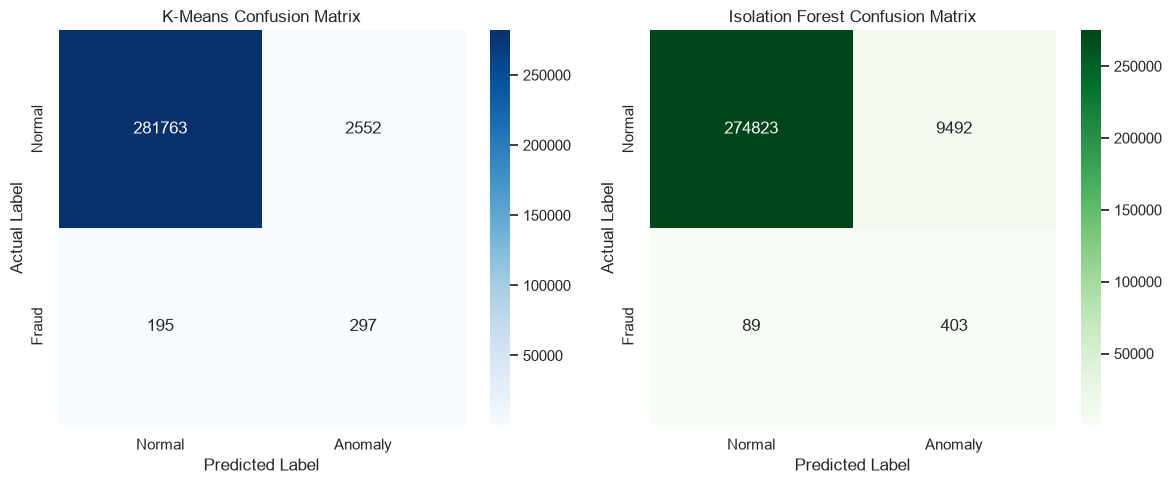

In [32]:
# Import the required evaluation function
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix for K-Means
kmeans_cm = confusion_matrix(
    actual_labels, kmeans_predictions, labels=[0, 1]
)

# Calculate the confusion matrix for Isolation Forest
isolation_cm = confusion_matrix(
    actual_labels, isolation_predictions, labels=[0, 1]
)

# Display both confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot the K-Means confusion matrix
sns.heatmap(
    kmeans_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Anomaly'],
    yticklabels=['Normal', 'Fraud']
    ,
    ax=axes[0]
)
axes[0].set_title('K-Means Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# Plot the Isolation Forest confusion matrix
sns.heatmap(
    isolation_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Normal', 'Anomaly'],
    yticklabels=['Normal', 'Fraud'],
    ax=axes[1]
)
axes[1].set_title('Isolation Forest Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

# Adjust spacing and display the plots
plt.tight_layout()
plt.show()

##### The confusion matrices show the performance of K-Means and Isolation Forest in identifying fraudulent transactions. K-Means correctly detected 297 fraudulent transactions, while Isolation Forest detected 403 fraudulent transactions. Isolation Forest missed fewer fraudulent transactions (89) compared to K-Means (195). However, Isolation Forest also produced more false positives. This indicates that Isolation Forest identifies more actual fraud cases but may also flag more legitimate transactions as suspicious.

#### 7.3 Precision and Recall
 ##### Precision and recall help evaluate fraud detection performance, especially when fraudulent transactions are rare.
##### - Precision: The proportion of transactions flagged as anomalous that are actually fraudulent.
##### - Recall: The proportion of all actual fraudulent transactions that the model successfully identifies.

In [33]:
# Import precision and recall evaluation functions
from sklearn.metrics import precision_score, recall_score

# Calculate precision and recall for K-Means
kmeans_precision = precision_score(
    actual_labels, kmeans_predictions, zero_division=0
)

kmeans_recall = recall_score(
    actual_labels, kmeans_predictions, zero_division=0
)

# Calculate precision and recall for Isolation Forest
isolation_precision = precision_score(
    actual_labels, isolation_predictions, zero_division=0
)

isolation_recall = recall_score(
    actual_labels, isolation_predictions, zero_division=0
)

# Create a table to compare the evaluation results
evaluation_results = pd.DataFrame({
    'Model': ['K-Means', 'Isolation Forest'],
    'Precision': [kmeans_precision, isolation_precision],
    'Recall': [kmeans_recall, isolation_recall]
})

# Display the results rounded to four decimal places
print("Precision and Recall Comparison:")
display(evaluation_results.round(4))

Precision and Recall Comparison:


,Model,Precision,Recall
0,K-Means,0.1042,0.6037
1,Isolation Forest,0.0407,0.8191


##### The precision and recall results show that K-Means achieved a precision of 10.42% and recall of 60.37%, whereas Isolation Forest achieved a precision of 4.07% and recall of 81.91%. Isolation Forest identified more actual fraudulent transactions, while K-Means produced fewer false alarms. Therefore, Isolation Forest is better at identifying fraudulent transactions, whereas K-Means provides higher precision.

#### 7.4 Which Model Is Better for Fraud Detection? Why?
 ##### Select the more suitable model by comparing its precision, recall, and confusion matrix results.

In [34]:
# Compare both models using their recall and precision
# Higher recall is preferred first to reduce missed fraudulent transactions
# Precision is used as the next criterion to compare false alarms

if isolation_recall > kmeans_recall:
    better_model = "Isolation Forest"
    reason = "It identifies a higher proportion of actual fraudulent transactions."

elif kmeans_recall > isolation_recall:
    better_model = "K-Means"
    reason = "It identifies a higher proportion of actual fraudulent transactions."

elif isolation_precision > kmeans_precision:
    better_model = "Isolation Forest"
    reason = "Both models have equal recall, but Isolation Forest has higher precision."

elif kmeans_precision > isolation_precision:
    better_model = "K-Means"
    reason = "Both models have equal recall, but K-Means has higher precision."

else:
    better_model = "Both models have equal precision and recall"
    reason = "Neither model is better based on these two metrics alone."

# Display the evaluation-based conclusion
print("Model selected for fraud detection:", better_model)
print("Reason:", reason)

Model selected for fraud detection: Isolation Forest
Reason: It identifies a higher proportion of actual fraudulent transactions.


##### Isolation Forest is selected as the better model for fraud detection because it achieves a higher recall of 81.91%, compared to 60.37% for K-Means. It successfully identifies 403 fraudulent transactions while K-Means identifies 297. Although Isolation Forest has lower precision and produces more false positives, it detects more actual fraudulent transactions. Therefore, Isolation Forest is more suitable when identifying fraudulent transactions is the primary objective.

### 8. Final Conclusion

#### 8.1 Business Perspective Summary

##### Credit card fraud detection helps financial institutions identify suspicious transactions and reduce financial losses. In this project, unsupervised learning techniques, K-Means and Isolation Forest, were applied to identify unusual transaction patterns without using actual fraud labels during model training.

##### The dataset contains 284,807 transactions, including 492 fraudulent transactions. Among the two methods, Isolation Forest identified 403 actual fraudulent transactions, achieving a recall of 81.91%. This shows that unsupervised learning can help financial institutions identify potentially fraudulent transactions and improve transaction monitoring. However, some legitimate transactions were also flagged as suspicious, so further investigation is necessary before confirming fraud.

#### 8.2 Recommendation

##### Based on the evaluation results, Isolation Forest is recommended as the preferred model for identifying suspicious credit card transactions because it achieved a higher recall of 81.91% compared to 60.37% for K-Means.

##### Although Isolation Forest produces more false positives, it identifies more actual fraudulent transactions and misses fewer fraud cases. Financial institutions can use this model as an initial fraud screening system. Transactions identified as suspicious should be reviewed further before taking action. Improving precision and reducing false alarms can make the system more effective in real-world applications.